**Implement a single-layer perceptron from scratch.**

In [14]:
import numpy as np
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score

In [15]:
# 1. Dataset (AND Gate logic)
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 0, 0, 1])

In [16]:
# 2. Initialize and train the Perceptron
# max_iter sets the epochs; tol handles early stopping if no progress is made
clf = Perceptron(max_iter=100, eta0=0.1, random_state=42)
clf.fit(X, y)

,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",100
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",0.1
,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [17]:
# 3. Evaluate the model
predictions = clf.predict(X)

In [18]:
print("--- Scikit-Learn Perceptron ---")
print(f"Learned Weights: {clf.coef_[0]}")
print(f"Learned Bias: {clf.intercept_[0]}")
print(f"Predictions: {predictions}")
print(f"Accuracy: {accuracy_score(y, predictions) * 100}%")

--- Scikit-Learn Perceptron ---
Learned Weights: [0.2 0.2]
Learned Bias: -0.20000000000000004
Predictions: [0 0 0 1]
Accuracy: 100.0%


    Inputs (X)           Weights (W)          Summation & Step Fn           Output (y)
   ------------         -------------        ---------------------        --------------

     [ X₁ ] ------------> ( w₁ = 0.2 ) -------\
                                               \
                                                +---> [ ∑ WX + b ] ---------> [ Predict (0 or 1) ]
                                               /         (Net Input)          (Step Activation)
     [ X₂ ] ------------> ( w₂ = 0.2 ) -------/              ^
                                                            |
                                                            |
     [ Bias ] ----------------------------------------------/
     ( X₀ = 1 ) ---------> (  b = -0.2 )


In [19]:
import numpy as np
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

In [20]:
# 1. Generate a complex, non-linear dataset
X, y = make_moons(n_samples=1000, noise=0.3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [21]:
# 2. Scale features (essential for stable neural network training)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [22]:
# 3. Test different activation functions
activations = ['identity', 'logistic', 'tanh', 'relu']
results = {}

In [23]:
for activation in activations:
    # Build a network with 2 hidden layers (10 neurons each)
    mlp = MLPClassifier(
        hidden_layer_sizes=(10, 10),
        activation=activation,
        solver='adam',
        max_iter=1000,
        random_state=42
    )
    mlp.fit(X_train_scaled, y_train)

    # Evaluate performance
    predictions = mlp.predict(X_test_scaled)
    results[activation] = accuracy_score(y_test, predictions)

In [24]:
# Print final metrics
print("--- Validation Accuracy Analysis ---")
for act, acc in results.items():
    print(f"{act.capitalize():<10} Activation Function: {acc * 100:.2f}%")

--- Validation Accuracy Analysis ---
Identity   Activation Function: 85.33%
Logistic   Activation Function: 85.67%
Tanh       Activation Function: 90.67%
Relu       Activation Function: 91.67%


In [25]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [26]:
# 1. Load and prep standard MNIST digit images
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0  # Normalize to scale [0, 1]

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [27]:
model = keras.Sequential([
    layers.Flatten(input_shape=(28, 28), name="Input_Flatten"),
    layers.Dense(128, activation='relu', name="Hidden_Layer_1"),
    layers.Dense(64, activation='relu', name="Hidden_Layer_2"),
    layers.Dense(10, activation='softmax', name="Output_Softmax")
])

/Users/pratikvilasgadhe/Desktop/Programming/AI_ML/.venv/lib/python3.13/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [28]:
# 3. Configure optimizer metrics
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [29]:
# Print visual network topology structure parameter summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Flatten (Flatten)         │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_1 (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_2 (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Softmax (Dense)          │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
# 4. Train model and cache training metadata logs
history = model.fit(x_train, y_train, epochs=10, validation_split=0.2, batch_size=64)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9129 - loss: 0.3063 - val_accuracy: 0.9489 - val_loss: 0.1685
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9615 - loss: 0.1291 - val_accuracy: 0.9628 - val_loss: 0.1190
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9733 - loss: 0.0885 - val_accuracy: 0.9692 - val_loss: 0.1009
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9794 - loss: 0.0676 - val_accuracy: 0.9705 - val_loss: 0.0954
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9837 - loss: 0.0507 - val_accuracy: 0.9716 - val_loss: 0.0967
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9873 - loss: 0.0412 - val_accuracy: 0.9732 - val_loss: 0.0880
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9891 - loss: 0.0348 - val_accuracy: 0.9718 - val_loss: 0.0976
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9912 - loss: 0.0275 - val_accuracy: 0.

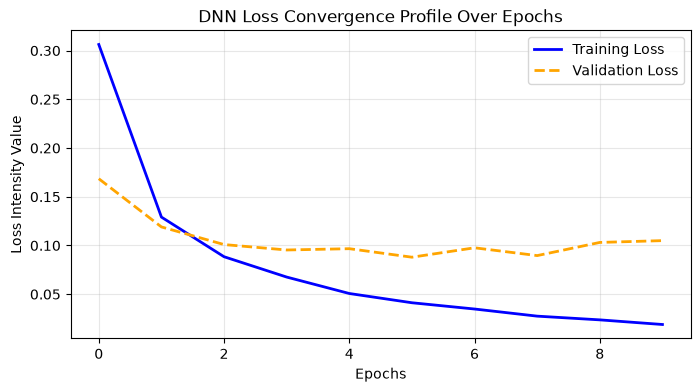

In [31]:
# --- LOSS VISUALIZATION ---
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Training Loss', color='blue', lw=2)
plt.plot(history.history['val_loss'], label='Validation Loss', color='orange', linestyle='--', lw=2)
plt.title('DNN Loss Convergence Profile Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss Intensity Value')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()